# EfficientNet B0–B7 Comparative Study
## Lung Cancer Detection on IQ-OTH/NCCD Dataset

This notebook trains and evaluates all 8 EfficientNet variants (B0 through B7) on the IQ-OTH/NCCD lung cancer CT scan dataset.
It includes full XAI validation (Grad-CAM, Grad-CAM++, Score-CAM, Eigen-CAM, Guided Grad-CAM) and a final comparative analysis dashboard.

**Dataset classes:** Benign cases · Malignant cases · Normal cases

**Models compared:** EfficientNet-B0, B1, B2, B3, B4, B5, B6, B7

In [1]:
# ==========================================
# CELL 1: MOUNT GOOGLE DRIVE
# ==========================================
from google.colab import drive
drive.mount('/content/drive')

# --- UPDATE THIS PATH TO MATCH YOUR DRIVE LOCATION ---
directory = '/content/drive/My Drive/Kaggle/IQ-OTH-NCCD/IQ-OTHNCCD-dataset/'
categories = ['Bengin cases', 'Malignant cases', 'Normal cases']

Mounted at /content/drive


In [2]:
# ==========================================
# CELL 2: INSTALL / IMPORT ALL DEPENDENCIES
# ==========================================
import os
import time
import random
import warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_curve,
    average_precision_score
)
from sklearn.preprocessing import label_binarize
from sklearn.utils import class_weight

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import (
    EfficientNetB0,
    #EfficientNetB1,
    #EfficientNetB2,
    EfficientNetB3,
    #EfficientNetB4,
    #EfficientNetB5,
    #EfficientNetB6,
    EfficientNetB7
)
from tensorflow.keras.applications.efficientnet import preprocess_input

warnings.filterwarnings('ignore')

# GPU memory growth
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print(f"TensorFlow version : {tf.__version__}")
print(f"GPUs available     : {len(gpus)}")
print(f"GPU name           : {gpus[0].name if gpus else 'No GPU — switch Runtime to GPU!'}")

TensorFlow version : 2.20.0
GPUs available     : 0
GPU name           : No GPU — switch Runtime to GPU!


In [3]:
# ==========================================
# CELL 3: MODEL CONFIGURATION TABLE
# ==========================================
# Each entry: (ModelClass, native_img_size, freeze_first_N_layers, model_name_string)
# img_size follows the EfficientNet paper's recommended input resolution.
# freeze_first_N_layers: freeze early stem layers; fine-tune deeper SE blocks.

MODEL_CONFIGS = [
    (EfficientNetB0, 224, 50,  'EfficientNet-B0', 'efficientnetb0'),
    #(EfficientNetB1, 240, 55,  'EfficientNet-B1', 'efficientnetb1'),
    #(EfficientNetB2, 260, 60,  'EfficientNet-B2', 'efficientnetb2'),
    (EfficientNetB3, 300, 65,  'EfficientNet-B3', 'efficientnetb3'),
    #(EfficientNetB4, 380, 70,  'EfficientNet-B4', 'efficientnetb4'),
    #(EfficientNetB5, 456, 80,  'EfficientNet-B5', 'efficientnetb5'),
    #(EfficientNetB6, 528, 90,  'EfficientNet-B6', 'efficientnetb6'),
    (EfficientNetB7, 600, 100, 'EfficientNet-B7', 'efficientnetb7'),
]

print("Model Configuration Summary")
print("-" * 65)
print(f"{'Model':<20} {'Input Size':>12} {'Frozen Layers':>14}")
print("-" * 65)
for cfg in MODEL_CONFIGS:
    print(f"{cfg[3]:<20} {str(cfg[1])+'x'+str(cfg[1]):>12} {cfg[2]:>14}")
print("-" * 65)
print("\nNOTE: B4-B7 require significantly more GPU memory.")
print("If OOM errors occur, reduce batch_size in CELL 4 (e.g., 8 or 4).")

Model Configuration Summary
-----------------------------------------------------------------
Model                  Input Size  Frozen Layers
-----------------------------------------------------------------
EfficientNet-B0           224x224             50
EfficientNet-B3           300x300             65
EfficientNet-B7           600x600            100
-----------------------------------------------------------------

NOTE: B4-B7 require significantly more GPU memory.
If OOM errors occur, reduce batch_size in CELL 4 (e.g., 8 or 4).


In [4]:
## ==========================================
# CELL 4: GLOBAL TRAINING HYPERPARAMETERS
# ==========================================
BATCH_SIZE    = 16    # Reduce to 8 if OOM on B5/B6/B7
EPOCHS        = 50    # EarlyStopping will terminate early
VAL_SPLIT     = 0.1
TEST_SIZE     = 0.2
RANDOM_SEED   = 42
LEARNING_RATE = 1e-3
DROPOUT_RATE  = 0.4
DENSE_UNITS   = 128
NUM_CLASSES   = 3

print("Hyperparameters set.")

Hyperparameters set.


In [5]:
# ==========================================
# CELL 5: DATA LOADING FUNCTION
# Loads images at the target resolution for each model.
# Returns normalised numpy arrays ready for EfficientNet.
# ==========================================
def load_data_for_size(img_size):
    """
    Loads all images from `directory` at `img_size x img_size`,
    applies EfficientNet's preprocess_input, and returns
    (X_train, X_test, y_train, y_test, class_weights_dict).
    """
    data = []
    for i, category in enumerate(categories):
        path = os.path.join(directory, category)
        for file in os.listdir(path):
            try:
                filepath = os.path.join(path, file)
                img = cv2.imread(filepath)
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, (img_size, img_size))
                img = preprocess_input(img.astype(np.float32))
                data.append([img, i])
            except Exception:
                pass

    random.seed(RANDOM_SEED)
    random.shuffle(data)

    X = np.array([d[0] for d in data])
    y = np.array([d[1] for d in data])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=y
    )

    weights = class_weight.compute_class_weight(
        'balanced', classes=np.unique(y_train), y=y_train
    )
    class_weights_dict = dict(enumerate(weights))

    print(f"  Loaded {len(X)} images at {img_size}x{img_size}")
    print(f"  Train: {len(X_train)} | Test: {len(X_test)}")
    print(f"  Class distribution: {dict(Counter(y_train))}")
    return X_train, X_test, y_train, y_test, class_weights_dict

print("Data loading function defined.")

Data loading function defined.


In [6]:
# ==========================================
# CELL 6: MODEL BUILDER
# ==========================================
def build_efficientnet(model_class, img_size, freeze_n, num_classes=NUM_CLASSES):
    """
    Builds an EfficientNet variant with a custom classification head.
    Freezes the first `freeze_n` layers; fine-tunes the rest.
    """
    base = model_class(
        weights='imagenet',
        include_top=False,
        input_shape=(img_size, img_size, 3)
    )
    base.trainable = True
    for layer in base.layers[:freeze_n]:
        layer.trainable = False

    model = models.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.BatchNormalization(),
        layers.Dropout(DROPOUT_RATE),
        layers.Dense(DENSE_UNITS, activation='relu'),
        layers.Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer=optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


def get_callbacks():
    return [
        callbacks.EarlyStopping(
            monitor='val_loss', patience=8, restore_best_weights=True, verbose=1
        ),
        callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.2, patience=4, verbose=1
        )
    ]

print("Model builder defined.")

Model builder defined.


In [7]:
# ==========================================
# CELL 7: XAI HELPER FUNCTIONS
# All XAI functions are model-agnostic via `base_layer_name`.
# ==========================================

# ---- Grad-CAM ----
def get_gradcam_heatmap(img_array, model, base_layer_name, last_conv_layer_name='top_activation'):
    base = model.get_layer(base_layer_name)
    feature_extractor = models.Model(
        inputs=base.input,
        outputs=[base.get_layer(last_conv_layer_name).output, base.output]
    )
    classifier_input = layers.Input(shape=base.output.shape[1:])
    x = classifier_input
    for layer in model.layers[1:]:
        x = layer(x)
    classifier_model = models.Model(inputs=classifier_input, outputs=x)

    with tf.GradientTape() as tape:
        inputs = tf.cast(img_array, tf.float32)
        last_conv_output, base_output = feature_extractor(inputs)
        tape.watch(last_conv_output)
        preds = classifier_model(base_output)
        class_channel = preds[:, tf.argmax(preds[0])]

    grads = tape.gradient(class_channel, last_conv_output)
    if grads is None:
        raise ValueError("Gradient is None — ensure base_model.trainable=True.")
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = last_conv_output[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-7)
    return heatmap.numpy()


# ---- Grad-CAM++ ----
def get_gradcam_plus_plus(img_array, model, base_layer_name, last_conv_layer_name='top_activation'):
    base = model.get_layer(base_layer_name)
    feature_extractor = models.Model(
        inputs=base.input,
        outputs=[base.get_layer(last_conv_layer_name).output, base.output]
    )
    classifier_input = layers.Input(shape=base.output.shape[1:])
    x = classifier_input
    for layer in model.layers[1:]:
        x = layer(x)
    classifier_model = models.Model(inputs=classifier_input, outputs=x)

    with tf.GradientTape() as tape:
        last_conv_output, base_output = feature_extractor(img_array)
        tape.watch(last_conv_output)
        preds = classifier_model(base_output)
        class_idx = tf.argmax(preds[0])
        class_output = preds[:, class_idx]

    grads = tape.gradient(class_output, last_conv_output)
    if grads is None:
        raise ValueError("Gradient is None.")
    first_derivative  = tf.exp(class_output) * grads
    second_derivative = tf.exp(class_output) * tf.pow(grads, 2)
    third_derivative  = tf.exp(class_output) * tf.pow(grads, 3)
    global_sum  = tf.reduce_sum(last_conv_output[0], axis=(0, 1)) + 1e-7
    alpha_num   = second_derivative[0]
    alpha_denom = second_derivative[0] * 2.0 + global_sum * third_derivative[0]
    alpha   = alpha_num / (alpha_denom + 1e-7)
    weights = tf.reduce_sum(alpha * tf.maximum(first_derivative[0], 0), axis=(0, 1))
    heatmap = tf.reduce_sum(weights * last_conv_output[0], axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-7)
    return heatmap.numpy()


# ---- Score-CAM ----
def get_scorecam(img_array, model, base_layer_name, img_size, last_conv_layer_name='top_activation'):
    base = model.get_layer(base_layer_name)
    feature_extractor = models.Model(
        inputs=base.input,
        outputs=base.get_layer(last_conv_layer_name).output
    )
    features = feature_extractor(img_array)
    upsampled = tf.image.resize(features, (img_size, img_size))
    max_v = tf.reduce_max(upsampled, axis=(1, 2), keepdims=True)
    min_v = tf.reduce_min(upsampled, axis=(1, 2), keepdims=True)
    norm  = (upsampled - min_v) / (max_v - min_v + 1e-7)
    scores = []
    for i in range(min(64, features.shape[-1])):
        masked = img_array * norm[0, :, :, i:i+1]
        preds  = model.predict(masked, verbose=0)
        scores.append(preds[0][np.argmax(preds[0])])
    heatmap = np.dot(features[0, :, :, :len(scores)], scores)
    heatmap = np.maximum(heatmap, 0)
    return heatmap / (np.max(heatmap) + 1e-7)


# ---- Eigen-CAM ----
def get_eigencam(img_array, model, base_layer_name, last_conv_layer_name='top_activation'):
    base = model.get_layer(base_layer_name)
    feature_extractor = models.Model(
        inputs=base.input,
        outputs=base.get_layer(last_conv_layer_name).output
    )
    features = feature_extractor(img_array)[0].numpy()
    flat     = features.reshape(-1, features.shape[-1])
    _, _, vh = np.linalg.svd(flat, full_matrices=False)
    heatmap  = (flat @ vh[0]).reshape(features.shape[0], features.shape[1])
    heatmap  = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-4)
    return heatmap


# ---- Guided Grad-CAM ----
def get_guided_gradcam(img_array, model, heatmap, img_size):
    with tf.GradientTape() as tape:
        inputs = tf.cast(img_array, tf.float32)
        tape.watch(inputs)
        preds    = model(inputs)
        class_idx = tf.argmax(preds[0])
        score    = preds[:, class_idx]
    grads = tape.gradient(score, inputs)[0]
    resized_heatmap = cv2.resize(heatmap, (img_size, img_size))
    guided_gc = grads.numpy() * resized_heatmap[..., np.newaxis]
    guided_gc = (guided_gc - guided_gc.min()) / (guided_gc.max() - guided_gc.min() + 1e-7)
    return guided_gc


print("XAI functions defined (Grad-CAM, Grad-CAM++, Score-CAM, Eigen-CAM, Guided Grad-CAM).")

XAI functions defined (Grad-CAM, Grad-CAM++, Score-CAM, Eigen-CAM, Guided Grad-CAM).


In [8]:
# ==========================================
# CELL 8: EVALUATION HELPER FUNCTIONS
# ==========================================

def plot_training_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history.history['accuracy'],     label='Train Acc',  color='green',   linestyle='--')
    axes[0].plot(history.history['val_accuracy'], label='Val Acc',    color='darkgreen')
    axes[0].set_title(f'{model_name}: Accuracy')
    axes[0].set_xlabel('Epochs'); axes[0].set_ylabel('Accuracy')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(history.history['loss'],     label='Train Loss', color='red',    linestyle='--')
    axes[1].plot(history.history['val_loss'], label='Val Loss',   color='darkred')
    axes[1].set_title(f'{model_name}: Loss')
    axes[1].set_xlabel('Epochs'); axes[1].set_ylabel('Cross-Entropy Loss')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.suptitle(f'{model_name} — Training History', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(y_test, y_pred, model_name):
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
                xticklabels=categories, yticklabels=categories)
    plt.title(f'Confusion Matrix: {model_name}')
    plt.ylabel('Actual'); plt.xlabel('Predicted')
    plt.tight_layout(); plt.show()


def plot_roc_pr_curves(y_test, y_probs, model_name):
    y_bin    = label_binarize(y_test, classes=[0, 1, 2])
    colors   = ['blue', 'red', 'green']
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    for i, color in enumerate(colors):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
        roc_auc     = auc(fpr, tpr)
        axes[0].plot(fpr, tpr, color=color, lw=2, label=f'{categories[i]} (AUC={roc_auc:.3f})')

        prec, rec, _ = precision_recall_curve(y_bin[:, i], y_probs[:, i])
        ap           = average_precision_score(y_bin[:, i], y_probs[:, i])
        axes[1].plot(rec, prec, color=color, lw=2, label=f'{categories[i]} (AP={ap:.3f})')

    axes[0].plot([0,1],[0,1],'k--',alpha=0.4)
    axes[0].set_title(f'ROC Curve: {model_name}')
    axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
    axes[0].legend(loc='lower right'); axes[0].grid(alpha=0.3)

    axes[1].set_title(f'Precision-Recall: {model_name}')
    axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
    axes[1].legend(loc='lower left'); axes[1].grid(alpha=0.3)

    plt.tight_layout(); plt.show()


def measure_latency(model, X_test):
    start = time.time()
    model.predict(X_test, verbose=0)
    return (time.time() - start) / len(X_test) * 1000  # ms/image


def count_params(model):
    return model.count_params()


print("Evaluation helpers defined.")

Evaluation helpers defined.


In [9]:
# ==========================================
# CELL 9: XAI PANEL (5 methods side-by-side)
# ==========================================
def run_xai_panel(model, X_test, y_test, img_size, base_layer_name, model_name, sample_idx=5):
    """
    Generates a 5-method XAI panel for one sample image.
    """
    sample_img  = np.expand_dims(X_test[sample_idx], axis=0)
    display_img = (X_test[sample_idx] - X_test[sample_idx].min()) / \
                  (X_test[sample_idx].max() - X_test[sample_idx].min())

    print(f"  Running XAI for {model_name} | Sample index={sample_idx} | Class={categories[y_test[sample_idx]]}")

    hm_gc   = get_gradcam_heatmap(sample_img, model, base_layer_name)
    hm_gcpp = get_gradcam_plus_plus(sample_img, model, base_layer_name)
    hm_sc   = get_scorecam(sample_img, model, base_layer_name, img_size)
    hm_eig  = get_eigencam(sample_img, model, base_layer_name)
    hm_ggc  = get_guided_gradcam(sample_img, model, hm_gc, img_size)

    titles   = ['Original CT', 'Grad-CAM', 'Grad-CAM++', 'Score-CAM', 'Eigen-CAM', 'Guided Grad-CAM']
    heatmaps = [None, hm_gc, hm_gcpp, hm_sc, hm_eig, None]  # None = no overlay

    fig, axes = plt.subplots(1, 6, figsize=(24, 4))
    fig.suptitle(f'XAI Validation — {model_name}  |  True: {categories[y_test[sample_idx]]}',
                 fontsize=12, fontweight='bold')

    for ax, title, hm in zip(axes, titles, heatmaps):
        ax.set_title(title, fontsize=9)
        ax.axis('off')
        if title == 'Guided Grad-CAM':
            ax.imshow(hm_ggc)
        elif hm is None:
            ax.imshow(display_img)
        else:
            ax.imshow(display_img)
            ax.imshow(cv2.resize(hm, (img_size, img_size)), alpha=0.5, cmap='jet')

    plt.tight_layout()
    plt.show()


print("XAI panel function defined.")

XAI panel function defined.



  TRAINING: EfficientNet-B0  (input=224x224)
[1/6] Loading data...
  Loaded 1097 images at 224x224
  Train: 877 | Test: 220
  Class distribution: {np.int64(1): 448, np.int64(2): 333, np.int64(0): 96}
[2/6] Building model...
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
  Total parameters: 4,219,046
[3/6] Training...
Epoch 1/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 183s 3s/step - accuracy: 0.7465 - loss: 0.8861 - val_accuracy: 0.6932 - val_loss: 0.5720 - learning_rate: 0.0010
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 133s 3s/step - accuracy: 0.8783 - loss: 0.4538 - val_accuracy: 0.8182 - val_loss: 0.3919 - learning_rate: 0.0010
Epoch 3/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 133s 3s/step - accuracy: 0.9062 - loss: 0.3432 - val_accuracy: 0.9205 - val_loss: 0.1417 - learning_rate: 0.0010
Epoch 4/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 145s 3s/step - accuracy: 0.9480 - loss: 0.1526 - val_accuracy: 0.9205 - val_loss: 0.1270 - learning_rate: 0.0010
Epoch 5/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 132s 3s/step - accuracy: 0.9645 - 

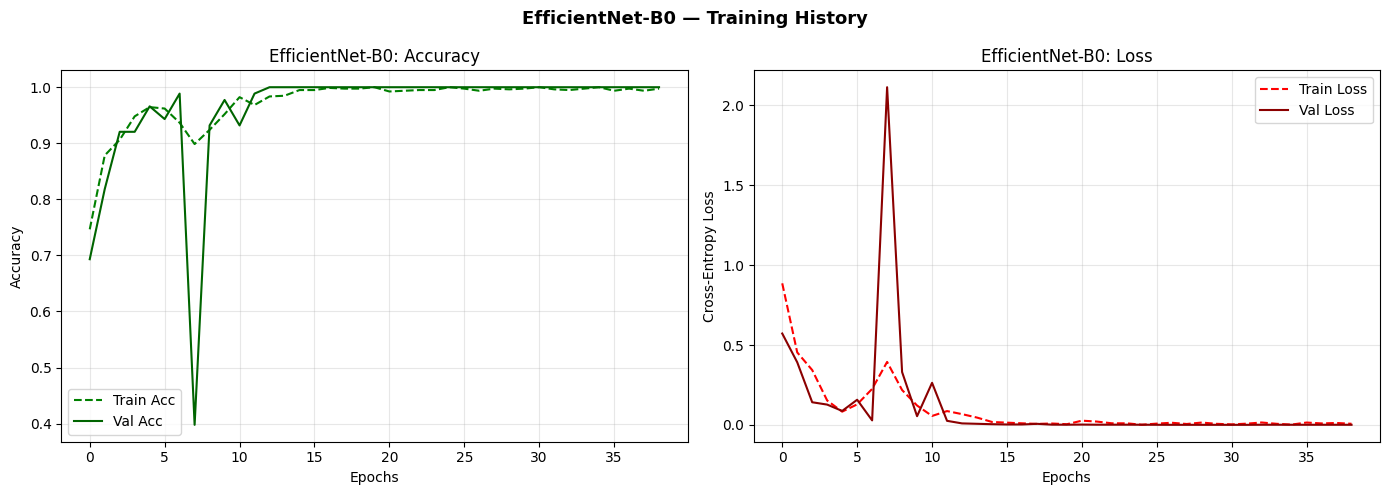

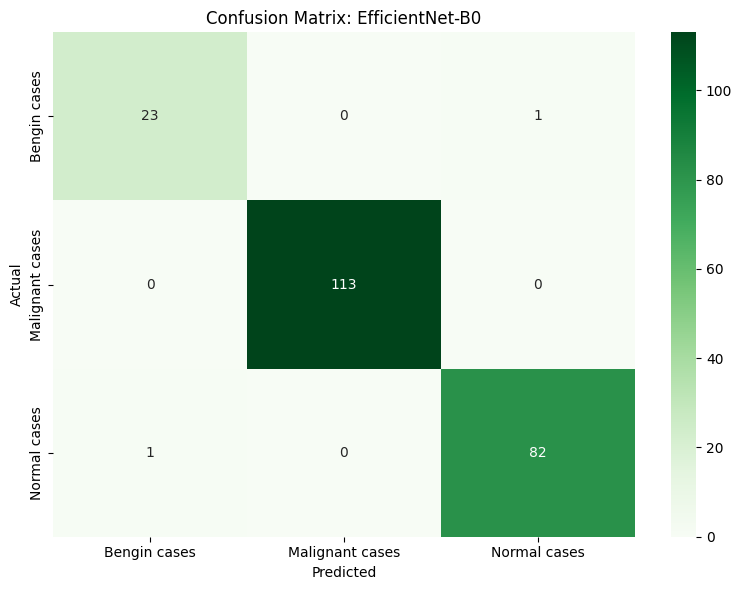

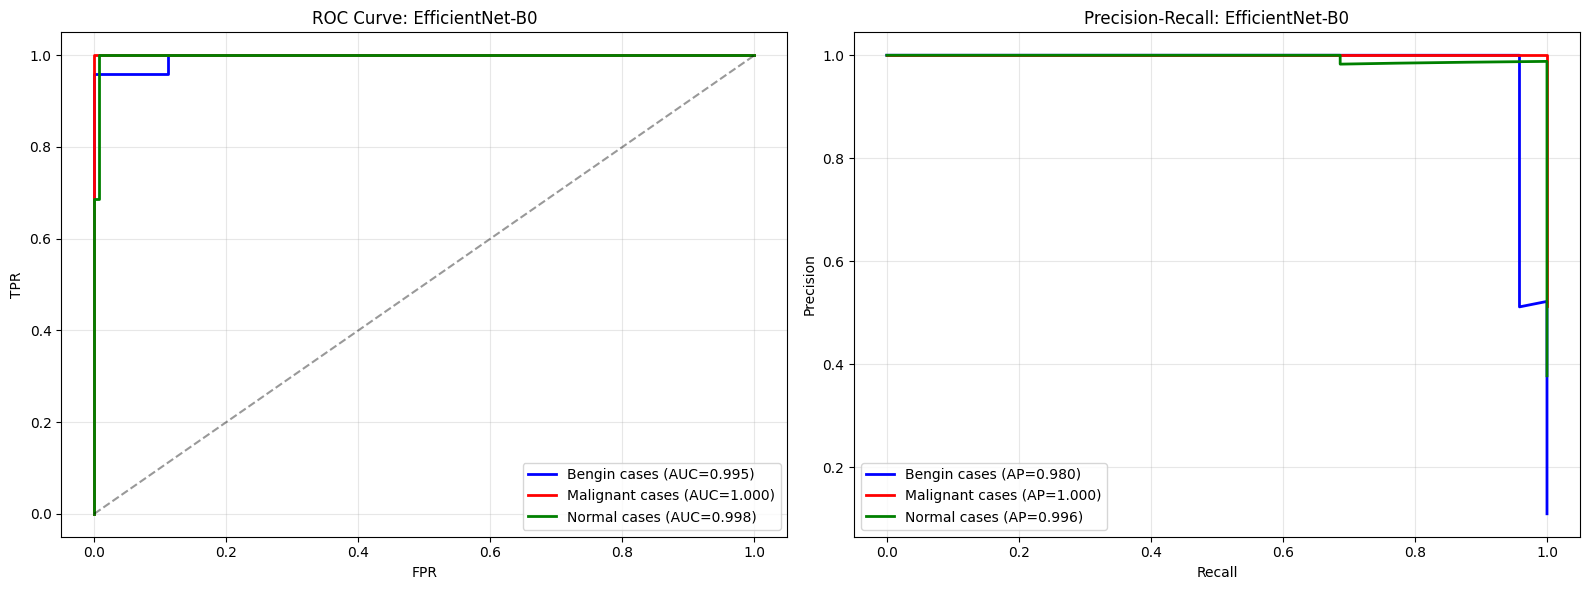

[6/6] Generating XAI explanations...
  Running XAI for EfficientNet-B0 | Sample index=5 | Class=Normal cases


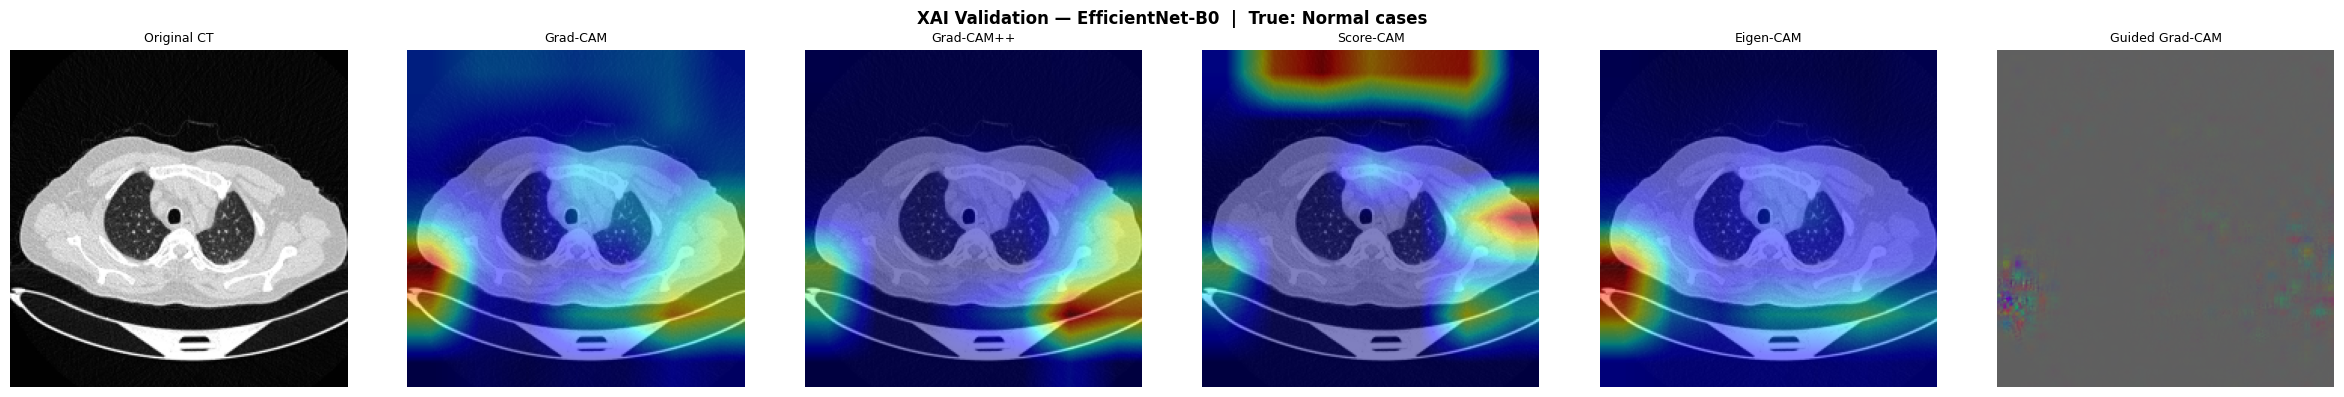


  TRAINING: EfficientNet-B3  (input=300x300)
[1/6] Loading data...
  Loaded 1097 images at 300x300
  Train: 877 | Test: 220
  Class distribution: {np.int64(1): 448, np.int64(2): 333, np.int64(0): 96}
[2/6] Building model...
43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
  Total parameters: 10,986,802
[3/6] Training...
Epoch 1/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 648s 12s/step - accuracy: 0.7326 - loss: 0.9994 - val_accuracy: 0.8182 - val_loss: 0.4980 - learning_rate: 0.0010
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 578s 12s/step - accuracy: 0.8606 - loss: 0.4564 - val_accuracy: 0.8750 - val_loss: 0.4447 - learning_rate: 0.0010
Epoch 3/50
10/50 ━━━━━━━━━━━━━━━━━━━━ 7:31 11s/step - accuracy: 0.9009 - loss: 0.4203

In [ ]:
# ==========================================
# CELL 10: MAIN TRAINING LOOP (B0 → B7)
# This cell trains all 8 variants sequentially.
# Each model's results are stored in `all_results`.
# Expected runtime: ~20–60 min on Colab T4 GPU.
# ==========================================

all_results = {}  # Stores metrics for the final comparison

for model_class, img_size, freeze_n, model_name, base_layer_name in MODEL_CONFIGS:

    print("\n" + "="*65)
    print(f"  TRAINING: {model_name}  (input={img_size}x{img_size})")
    print("="*65)

    # ---- 1. Load data at this model's native resolution ----
    print("[1/6] Loading data...")
    X_train, X_test, y_train, y_test, cw_dict = load_data_for_size(img_size)

    # ---- 2. Build & summarise model ----
    print("[2/6] Building model...")
    model = build_efficientnet(model_class, img_size, freeze_n)
    total_params = count_params(model)
    print(f"  Total parameters: {total_params:,}")

    # ---- 3. Train ----
    print("[3/6] Training...")
    t0 = time.time()
    history = model.fit(
        X_train, y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=VAL_SPLIT,
        class_weight=cw_dict,
        callbacks=get_callbacks(),
        verbose=1
    )
    train_time = time.time() - t0
    print(f"  Training time: {train_time:.1f}s  |  Epochs run: {len(history.history['accuracy'])}")

    # ---- 4. Evaluate ----
    print("[4/6] Evaluating...")
    y_probs = model.predict(X_test, verbose=0)
    y_preds = np.argmax(y_probs, axis=1)
    latency = measure_latency(model, X_test)

    report  = classification_report(y_test, y_preds, target_names=categories, output_dict=True)
    macro_f1   = report['macro avg']['f1-score']
    macro_prec = report['macro avg']['precision']
    macro_rec  = report['macro avg']['recall']
    accuracy   = report['accuracy']

    # ROC AUC (macro-average)
    y_bin = label_binarize(y_test, classes=[0, 1, 2])
    roc_aucs = [auc(*roc_curve(y_bin[:, i], y_probs[:, i])[:2]) for i in range(3)]
    macro_auc = np.mean(roc_aucs)

    print(f"  Accuracy : {accuracy:.4f}")
    print(f"  Macro F1 : {macro_f1:.4f}")
    print(f"  Macro AUC: {macro_auc:.4f}")
    print(f"  Latency  : {latency:.2f} ms/image")
    print(classification_report(y_test, y_preds, target_names=categories))

    # ---- 5. Visualisations ----
    print("[5/6] Plotting training history, confusion matrix, ROC/PR curves...")
    plot_training_history(history, model_name)
    plot_confusion_matrix(y_test, y_preds, model_name)
    plot_roc_pr_curves(y_test, y_probs, model_name)

    # ---- 6. XAI Panel ----
    print("[6/6] Generating XAI explanations...")
    try:
        run_xai_panel(model, X_test, y_test, img_size, base_layer_name, model_name, sample_idx=5)
    except Exception as e:
        print(f"  XAI panel skipped for {model_name}: {e}")

    # ---- Store results ----
    all_results[model_name] = {
        'accuracy'    : accuracy,
        'macro_f1'    : macro_f1,
        'macro_prec'  : macro_prec,
        'macro_rec'   : macro_rec,
        'macro_auc'   : macro_auc,
        'latency_ms'  : latency,
        'params'      : total_params,
        'train_time_s': train_time,
        'epochs_run'  : len(history.history['accuracy']),
        'img_size'    : img_size,
    }

    # Free GPU memory before next model
    del model
    tf.keras.backend.clear_session()

print("\n" + "="*65)
print("  ALL MODELS TRAINED — proceeding to comparison dashboard")
print("="*65)

In [ ]:
# ==========================================
# CELL 11: FINAL COMPARATIVE ANALYSIS DASHBOARD
# ==========================================
import pandas as pd

df = pd.DataFrame(all_results).T
df.index.name = 'Model'
df = df.reset_index()
df[['accuracy','macro_f1','macro_prec','macro_rec','macro_auc']] = \
    df[['accuracy','macro_f1','macro_prec','macro_rec','macro_auc']].astype(float).round(4)
df['latency_ms']   = df['latency_ms'].astype(float).round(2)
df['train_time_s'] = df['train_time_s'].astype(float).round(1)
df['params_M']     = (df['params'].astype(float) / 1e6).round(2)
df['img_size']     = df['img_size'].astype(int)

print("\n" + "="*95)
print("COMPARATIVE PERFORMANCE TABLE — EfficientNet B0 to B7 on IQ-OTH/NCCD Lung Cancer Dataset")
print("="*95)
display_cols = ['Model','img_size','params_M','accuracy','macro_f1','macro_auc',
                'macro_prec','macro_rec','latency_ms','train_time_s','epochs_run']
print(df[display_cols].to_string(index=False))
print("="*95)

best_acc  = df.loc[df['accuracy'].idxmax(),  'Model']
best_f1   = df.loc[df['macro_f1'].idxmax(),  'Model']
best_auc  = df.loc[df['macro_auc'].idxmax(), 'Model']
best_lat  = df.loc[df['latency_ms'].idxmin(),'Model']

print(f"\nBest Accuracy    : {best_acc}  ({df.loc[df['accuracy'].idxmax(),'accuracy']:.4f})")
print(f"Best Macro F1    : {best_f1}  ({df.loc[df['macro_f1'].idxmax(),'macro_f1']:.4f})")
print(f"Best Macro AUC   : {best_auc}  ({df.loc[df['macro_auc'].idxmax(),'macro_auc']:.4f})")
print(f"Lowest Latency   : {best_lat}  ({df.loc[df['latency_ms'].idxmin(),'latency_ms']:.2f} ms/img)")

NameError: name 'all_results' is not defined

In [ ]:
# ==========================================
# CELL 12: COMPARISON CHARTS
# ==========================================
model_names = df['Model'].tolist()
x = np.arange(len(model_names))
bar_w = 0.18
colors = ['#2ecc71','#e74c3c','#3498db','#9b59b6']

# ---- Chart 1: Accuracy / F1 / AUC / Recall ----
fig, ax = plt.subplots(figsize=(14, 6))
metrics = [('accuracy','Accuracy'),('macro_f1','Macro F1'),
           ('macro_auc','Macro AUC'),('macro_rec','Macro Recall')]
for j, (col, label) in enumerate(metrics):
    ax.bar(x + j*bar_w, df[col], bar_w, label=label, color=colors[j], alpha=0.85)
ax.set_xticks(x + bar_w*1.5)
ax.set_xticklabels(model_names, rotation=20, ha='right')
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score')
ax.set_title('EfficientNet B0–B7: Classification Performance Comparison', fontsize=13, fontweight='bold')
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

# ---- Chart 2: Latency vs Parameters ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(model_names, df['latency_ms'], color='#e67e22', alpha=0.85)
axes[0].set_title('Inference Latency (ms/image)', fontweight='bold')
axes[0].set_ylabel('ms / image')
axes[0].set_xticklabels(model_names, rotation=20, ha='right')
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(model_names, df['params_M'], color='#8e44ad', alpha=0.85)
axes[1].set_title('Model Size (Million Parameters)', fontweight='bold')
axes[1].set_ylabel('Parameters (M)')
axes[1].set_xticklabels(model_names, rotation=20, ha='right')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout(); plt.show()

# ---- Chart 3: Accuracy vs Model Size (efficiency frontier) ----
fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(df['params_M'], df['accuracy'],
                     c=df['latency_ms'], cmap='RdYlGn_r',
                     s=200, edgecolors='black', linewidths=0.7)
for _, row in df.iterrows():
    ax.annotate(row['Model'].replace('EfficientNet-','B'),
                (row['params_M'], row['accuracy']),
                textcoords='offset points', xytext=(6, 4), fontsize=9)
plt.colorbar(scatter, ax=ax, label='Latency (ms/img)')
ax.set_xlabel('Model Parameters (M)')
ax.set_ylabel('Test Accuracy')
ax.set_title('Accuracy vs Model Size\n(colour = inference latency)', fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ---- Chart 4: Training time ----
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(model_names, df['train_time_s'], color='#1abc9c', alpha=0.85)
ax.set_xlabel('Training Time (seconds)')
ax.set_title('Total Training Time per Model', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
# ==========================================
# CELL 13: RANKING SUMMARY & RECOMMENDATION
# ==========================================
print("\n" + "="*70)
print("  FINAL RANKING — EfficientNet B0 to B7")
print("  IQ-OTH/NCCD Lung Cancer Detection")
print("="*70)

# Composite score: 40% Accuracy + 30% F1 + 20% AUC + 10% (1 - norm_latency)
df['norm_latency'] = (df['latency_ms'] - df['latency_ms'].min()) / \
                     (df['latency_ms'].max() - df['latency_ms'].min() + 1e-9)
df['composite']    = (0.40 * df['accuracy'] +
                      0.30 * df['macro_f1']  +
                      0.20 * df['macro_auc'] +
                      0.10 * (1 - df['norm_latency'])).round(4)

df_rank = df[['Model','accuracy','macro_f1','macro_auc','latency_ms','params_M','composite']]\
            .sort_values('composite', ascending=False).reset_index(drop=True)
df_rank.index += 1
df_rank.index.name = 'Rank'

print(df_rank.to_string())
print("\nComposite score = 40% Accuracy + 30% F1 + 20% AUC + 10% (1-Norm.Latency)")

winner = df_rank.iloc[0]
print("\n" + "-"*70)
print(f"  RECOMMENDED MODEL: {winner['Model']}")
print(f"  Accuracy: {winner['accuracy']:.4f} | F1: {winner['macro_f1']:.4f} | "
      f"AUC: {winner['macro_auc']:.4f} | Latency: {winner['latency_ms']:.2f}ms")
print("-"*70)

In [ ]:
# ==========================================
# CELL 14: OPTIONAL — SAVE RESULTS TO CSV
# ==========================================
save_path = '/content/drive/My Drive/Kaggle/IQ-OTH-NCCD/efficientnet_b0_b7_results.csv'
df_rank.to_csv(save_path)
print(f"Results saved to: {save_path}")